In [111]:
import cv2
import os
from google.colab.patches import cv2_imshow
from google. colab import runtime
import numpy as np
import PIL
from PIL import Image
import glob
import pathlib
from matplotlib import pyplot as plt
import tensorflow as tf
from tensorflow import keras
from keras import layers
from keras.models import Sequential
from google.colab import drive
drive.mount("/content/drive", force_remount=True)

Mounted at /content/drive


In [112]:
folder_path = '/content/drive/My Drive/kilobot_images/ref10'
image_files = [f for f in os.listdir(folder_path) if f.endswith(('.jpg', '.jpeg', '.png', '.bmp', '.tiff'))]

# Filter image files to keep only those starting with 'ref9_repeat'
filtered_image_files = [f for f in image_files if f.startswith('ref10_connectivity2')]

images = {}
for img_file in filtered_image_files:
    img_path = os.path.join(folder_path, img_file)
    img = cv2.imread(img_path)
    if img is not None:
        images[img_file] = img
    else:
        print(f"Warning: Could not load image {img_file}")

print(f"Loaded {len(images)} images.")

Loaded 1 images.


ref10_connectivity2.png
inv min: 0 max: 228
inv dtype: uint8


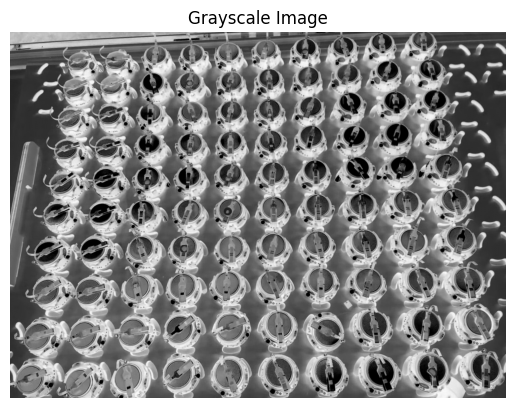

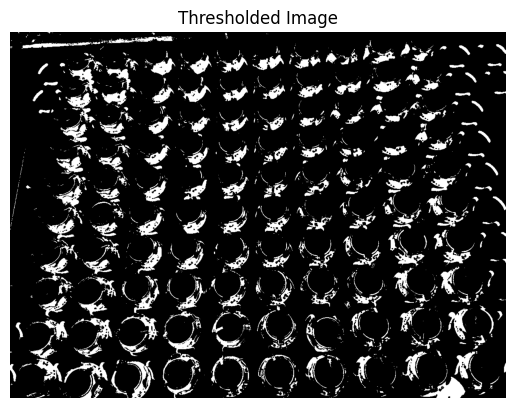

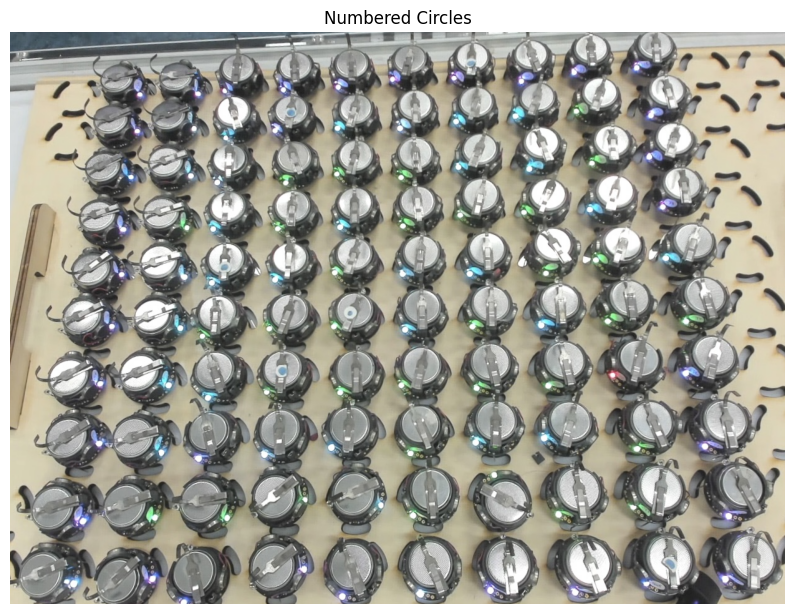

In [117]:
image_number = 0
image_name = list(images.keys())[image_number] #This gets an image that the user defines
print(image_name)
#Gets the image from drive
im = list(images.items())[image_number][1]
#cv2_imshow(image)

gray = cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)
inv = cv2.bitwise_not(gray)

print("inv min:", inv.min(), "max:", inv.max())
print("inv dtype:", inv.dtype)

if inv.dtype != np.uint8:
    inv = (inv * 255).astype(np.uint8)  # Normalize if needed

plt.imshow(inv, cmap='gray')
plt.title("Grayscale Image")
plt.axis('off')
plt.show()

# Optional: apply a binary threshold to isolate dark regions
_, thresh = cv2.threshold(inv, 180, 255, cv2.THRESH_BINARY)
blurred = cv2.medianBlur(thresh, 5)

plt.imshow(thresh, cmap='gray', vmin=0, vmax=255)
plt.title("Thresholded Image")
plt.axis('off')
plt.show()

circles = cv2.HoughCircles(
    blurred,
    cv2.HOUGH_GRADIENT,
    dp=1.5,               # Inverse resolution ratio
    minDist=150,           # Minimum distance between detected centers
    param1=22,            # Upper threshold for internal edge detection - lower = less fussy
    param2=27,            # Accumulator threshold for center detection - lower = less fussy
    minRadius=80,          # Minimum radius to detect
    maxRadius=100         # Maximum radius to detect
)

circles = cv2.HoughCircles(
    blurred,
    cv2.HOUGH_GRADIENT,
    dp=1.5,
    minDist=50,
    param1=100,    # Edge detection threshold
    param2=30,     # Center detection threshold
    minRadius=20,  # Expected min radius of robots
    maxRadius=35   # Expected max radius of robots
)

image_with_numbers = im.copy()
circle_centers = []

if circles is not None:
    circles = np.round(circles[0, :]).astype("int")
    for idx, (x, y, r) in enumerate(circles, start=1):
        circle_centers.append({"idx": idx, "x": x, "y": y})
        # Draw the circle outline
        cv2.circle(image_with_numbers, (x, y), r, (0, 255, 0), 2)

        # Draw the center of the circle
        cv2.circle(image_with_numbers, (x, y), 2, (0, 0, 255), 3)

        # Put the number near the circle (offset so it's readable)
        cv2.putText(
            image_with_numbers,
            str(idx),
            (x - 10, y - 10),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.8,
            (255, 0, 0),
            2,
        )

# Show the result
plt.figure(figsize=(10, 10))
plt.imshow(cv2.cvtColor(image_with_numbers, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.title("Numbered Circles")
plt.show()

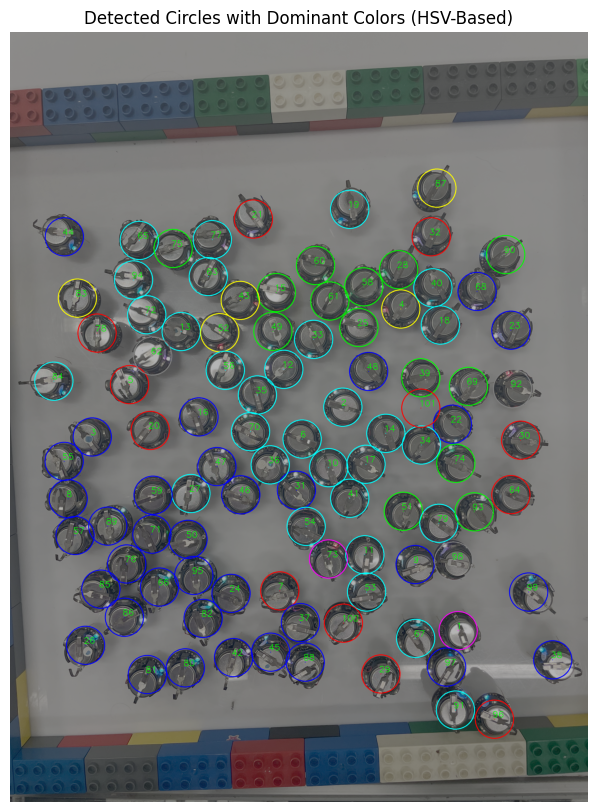

In [ ]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

circle_data = []

# Define HSV hue ranges (OpenCV uses H in [0,179])
color_hue_ranges = {
    "red":     [(0, 10), (160, 180)],
    "yellow":  [(25, 35)],
    "green":   [(40, 85)],
    "cyan":    [(85, 100)],
    "blue":    [(100, 130)],
    "magenta": [(140, 160)],
    "white":   [],  # handled separately
}

# Color map for drawing (BGR)
color_map = {
    "red":     (0, 0, 255),
    "green":   (0, 255, 0),
    "blue":    (255, 0, 0),
    "cyan":    (255, 255, 0),
    "magenta": (255, 0, 255),
    "yellow":  (0, 255, 255),
    "white":   (255, 255, 255),
    "unknown": (128, 128, 128),
}

# Function to classify dominant HSV color
def get_dominant_hsv_color(mean_bgr):
    mean_bgr_reshaped = np.uint8([[mean_bgr]])
    mean_hsv = cv2.cvtColor(mean_bgr_reshaped, cv2.COLOR_BGR2HSV)[0, 0]
    h, s, v = mean_hsv

    if v > 200 and s < 30:
        return "white"

    for color_name, ranges in color_hue_ranges.items():
        for low, high in ranges:
            if low <= h <= high:
                return color_name
    return "unknown"

# Detect color in each circle
if circle_centers is not None:
    for circle in circle_centers:
        idx = circle["idx"]
        x = circle["x"]
        y = circle["y"]
        r = 100

        # Create circular mask
        mask = np.zeros(im.shape[:2], dtype=np.uint8)
        cv2.circle(mask, (x, y), r, 255, thickness=-1)

        # Compute mean BGR color
        mean_bgr = np.array(cv2.mean(im, mask=mask)[:3])

        # Get dominant color using HSV
        dominant_color = get_dominant_hsv_color(mean_bgr)

        circle_data.append({
            "idx": idx,
            "x": x,
            "y": y,
            "radius": r,
            "dominant_color": dominant_color,
            "mean_bgr": mean_bgr.astype(int).tolist()
        })

# # === Draw results ===
# image_with_colors = im.copy()

# for circle in circle_data:
#     x, y = circle["x"], circle["y"]
#     r = circle["radius"]
#     idx = circle["idx"]
#     color = color_map.get(circle["dominant_color"], (0, 255, 0))

#     # Draw circle and label
#     cv2.circle(image_with_colors, (x, y), r, color, 3)
#     cv2.circle(image_with_colors, (x, y), 2, color, -1)
#     cv2.putText(image_with_colors, str(idx), (x - 10, y - 10),
#                 cv2.FONT_HERSHEY_SIMPLEX, 1.5, (0, 255, 0), 2)

# # === Show result ===
# plt.figure(figsize=(10, 10))
# plt.imshow(cv2.cvtColor(image_with_colors, cv2.COLOR_BGR2RGB))
# plt.axis('off')
# plt.title("Detected Circles with Dominant Colors (HSV-Based)")
# plt.show()


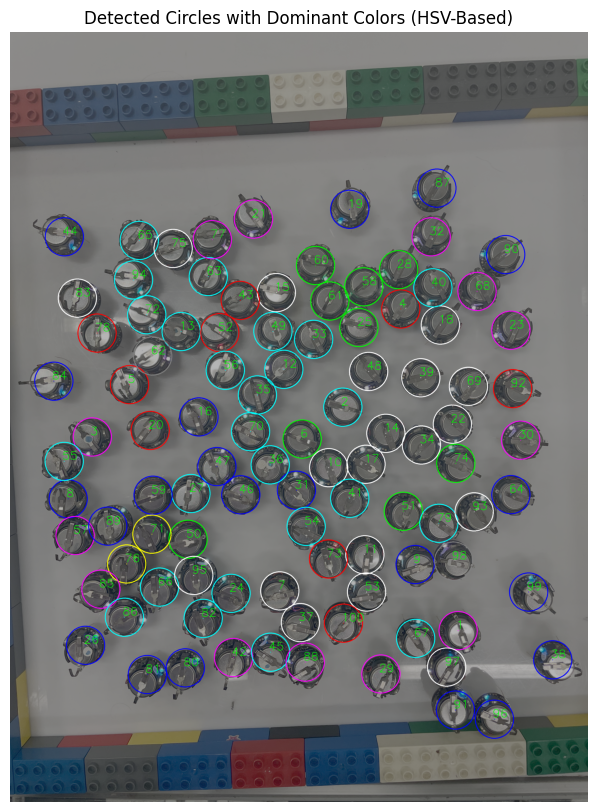

In [ ]:
image_with_colors = im.copy()

for circle in circle_data:
    x, y = circle["x"], circle["y"]
    r = circle["radius"]
    idx = circle["idx"]
    color = color_map.get(circle["dominant_color"], (0, 255, 0))

    # Draw circle and label
    cv2.circle(image_with_colors, (x, y), r, color, 3)
    cv2.circle(image_with_colors, (x, y), 2, color, -1)
    cv2.putText(image_with_colors, str(idx), (x - 10, y - 10),
                cv2.FONT_HERSHEY_SIMPLEX, 2, (0, 255, 0), 2)

# === Show result ===
plt.figure(figsize=(10, 10))
plt.imshow(cv2.cvtColor(image_with_colors, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.title("Detected Circles with Dominant Colors (HSV-Based)")
plt.show()

In [ ]:
idx = 97
circle_data[idx - 1]["dominant_color"] = "magenta"

In [ ]:
idx_to_remove = 101
circle_data = [circle for circle in circle_data if circle.get("idx") != idx_to_remove]


(np.float64(-0.5), np.float64(3023.5), np.float64(4031.5), np.float64(-0.5))

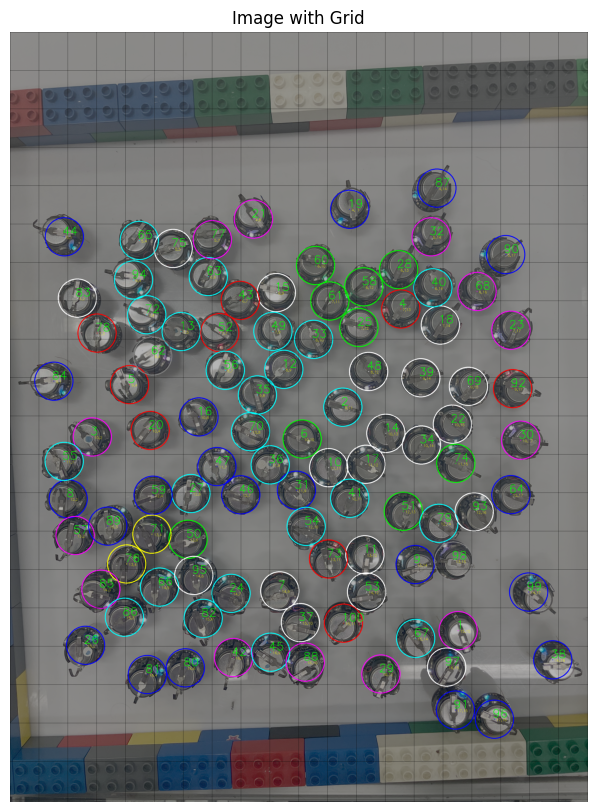

In [ ]:
import math

img_h, img_w = image_with_colors.shape[:2]

# Desired number of grid cells in each dimension
num_cols = 20
num_rows = 20

# Adjusted cell size (ensures perfect fit, no overlap or leftover space)
cell_width = img_w // num_cols
cell_height = img_h // num_rows

image_with_grid = image_with_colors.copy()

# Draw vertical lines
for x in range(0, img_w, cell_width):
    cv2.line(image_with_grid, (x, 0), (x, img_h), (0, 0, 0), 1)

# Draw horizontal lines
for y in range(0, img_h, cell_height):
    cv2.line(image_with_grid, (0, y), (img_w, y), (0, 0, 0), 1)

# Show image with grid lines
plt.figure(figsize=(30, 10))
plt.imshow(cv2.cvtColor(image_with_grid, cv2.COLOR_BGR2RGB))
plt.title("Image with Grid")
plt.axis("off")

In [ ]:
for circle in circle_data:
    x, y = circle["x"], circle["y"]
    col = x // cell_width
    row = y // cell_height
    circle["grid_cell"] = (int(row), int(col))  # Store as (row, col)

    # Optional: draw cell number on the image
    cell_text = f"{int(row)},{int(col)}"
    cv2.putText(
        image_with_colors,
        cell_text,
        (x + 10, y + 10),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.6,
        (0, 255, 255),
        1
    )

In [ ]:

# Build grid
grid_result = [[0 for _ in range(num_cols)] for _ in range(num_rows)]
for circle in circle_data:
    row, col = circle["grid_cell"]
    color = circle["dominant_color"]
    grid_result[row][col] = color

# Find rows with at least one non-zero entry
non_empty_rows = [i for i, row in enumerate(grid_result) if any(cell != 0 for cell in row)]

# Crop top and bottom
if non_empty_rows:
    top_row = min(non_empty_rows)
    bottom_row = max(non_empty_rows) + 1
    cropped_grid = grid_result[top_row:bottom_row]
else:
    cropped_grid = []

In [ ]:
color_map_num = {
    "red":     10,
    "green":   8,
    "blue":    4,
    "cyan":    7,
    "magenta": 5,
    "yellow":  9,
    "white":   6,
    0: 0,
}
numeric_grid = [[color_map_num[cell] for cell in row] for row in cropped_grid]
show_array = np.array(numeric_grid)

In [ ]:
numeric_grid

[[0, 0, 0, 0, 0, 0, 0, 0, 5, 0, 0, 4, 0, 0, 4, 0, 0, 0, 0, 0],
 [0, 4, 0, 0, 7, 6, 0, 5, 0, 0, 0, 0, 0, 0, 5, 0, 0, 4, 0, 0],
 [0, 0, 6, 0, 7, 0, 7, 10, 0, 6, 8, 0, 8, 8, 7, 0, 5, 0, 0, 0],
 [0, 0, 0, 6, 6, 8, 0, 10, 0, 7, 0, 8, 8, 10, 6, 0, 0, 5, 0, 0],
 [0, 0, 0, 0, 5, 0, 0, 7, 0, 5, 7, 0, 6, 0, 0, 0, 0, 0, 0, 0],
 [0, 4, 0, 0, 5, 0, 0, 0, 7, 0, 0, 7, 0, 0, 6, 6, 0, 10, 0, 0],
 [0, 0, 5, 0, 10, 0, 4, 0, 7, 0, 8, 0, 0, 6, 6, 6, 0, 5, 0, 0],
 [0, 7, 0, 0, 0, 0, 0, 4, 0, 7, 0, 6, 6, 0, 0, 8, 0, 0, 0, 0],
 [0, 0, 4, 4, 4, 0, 7, 4, 0, 0, 7, 7, 0, 6, 7, 0, 6, 4, 0, 0],
 [0, 0, 5, 0, 9, 0, 8, 0, 0, 0, 0, 10, 6, 0, 6, 5, 0, 0, 0, 0],
 [0, 0, 0, 5, 0, 7, 6, 7, 0, 6, 0, 0, 6, 0, 0, 0, 0, 4, 0, 0],
 [0, 0, 4, 7, 0, 0, 7, 0, 0, 0, 6, 10, 0, 0, 7, 5, 0, 0, 0, 0],
 [0, 0, 0, 0, 4, 0, 4, 5, 0, 7, 5, 0, 5, 0, 0, 6, 0, 0, 4, 0],
 [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 4, 4, 0, 0, 0]]

In [ ]:
reference_grid = np.array([ # using the same layout from pattern as template
    [0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0],
    [2, 1, 1, 1, 0, 0, 1, 0, 1, 0, 1, 0],
    [1, 1, 0, 1, 2, 2, 1, 1, 2, 2, 0, 0],
    [0, 1, 1, 2, 0, 2, 1, 1, 2, 0, 2, 0],
    [1, 2, 0, 0, 2, 2, 0, 1, 2, 2, 2, 0],
    [2, 0, 1, 2, 2, 2, 1, 1, 0, 2, 2, 0],
    [2, 0, 0, 2, 0, 2, 1, 1, 1, 2, 0, 0],
    [2, 0, 1, 1, 2, 2, 2, 0, 1, 1, 1, 0],
    [2, 1, 1, 1, 0, 2, 2, 2, 1, 1, 0, 0],
    [0, 2, 1, 2, 2, 2, 0, 2, 0, 0, 0, 1],
    [2, 2, 0, 2, 0, 1, 2, 0, 2, 1, 0, 2],
    [0, 0, 1, 2, 2, 0, 2, 2, 0, 1, 0, 0],
    [0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 2, 0]
])

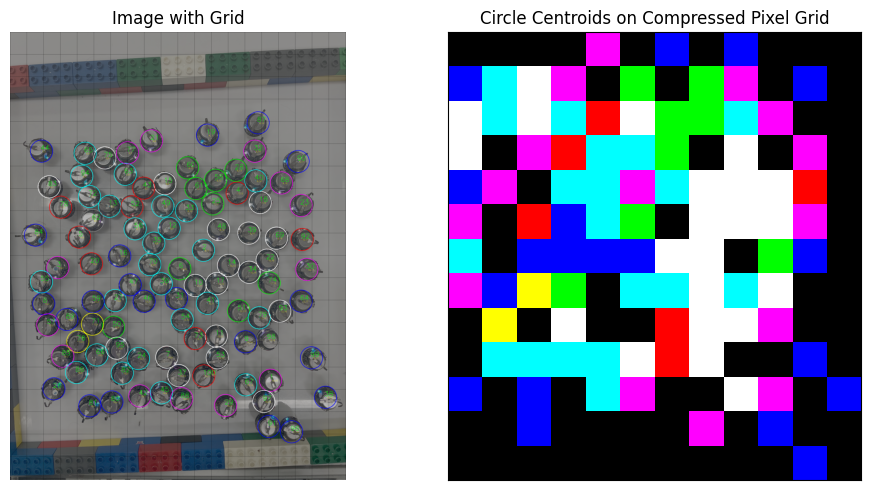

In [ ]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

# --- Sample input ---
# Replace with your actual data:
# circle_data = [{'x': ..., 'y': ..., 'dominant_color': 'red'/'blue'/...}, ...]

coords = np.array([[c['x'], c['y']] for c in circle_data])
colors = [c['dominant_color'] for c in circle_data]

# Step 1: Shift so min coordinate is (0,0)
coords -= coords.min(axis=0)

# Step 2: Convert real distances to grid locations (1 unit per ~150 px)
circle_spacing = 230  # threshold for adjacency
grid_coords = (coords / circle_spacing).astype(int)

# Step 3: Determine grid size
grid_w = grid_coords[:, 0].max() + 1
grid_h = grid_coords[:, 1].max() + 1

# Step 4: Create blank grid image
img = np.zeros((grid_h, grid_w, 3), dtype=np.uint8)

# Step 5: Draw each circle as 1 pixel in the grid
color_map = {
    "red":     (255, 0, 0),
    "green":   (0, 255, 0),
    "blue":    (0, 0, 255),
    "cyan":    (0, 255, 255),
    "magenta": (255, 0, 255),
    "yellow":  (255, 255, 0),
    "white":   (255, 255, 255),
    "unknown": (128, 128, 128),
}

for (x, y), c in zip(grid_coords, colors):
    img[y, x] = color_map.get(c, (0, 255, 0))

# Optional: Upscale for better visualization
img_big = cv2.resize(img, (grid_w * 10, grid_h * 10), interpolation=cv2.INTER_NEAREST)

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(image_with_grid, cv2.COLOR_BGR2RGB))
plt.title("Image with Grid")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(img_big)
plt.title("Circle Centroids on Compressed Pixel Grid")
plt.xticks([])
plt.yticks([])
plt.tight_layout()
plt.show()


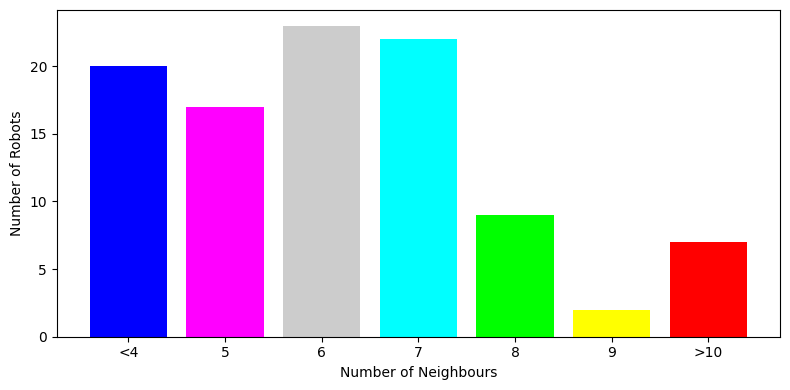

In [ ]:
import matplotlib.pyplot as plt
from collections import Counter
import re

# Your circle data dominant colors (example)
dominant_colors = [c['dominant_color'] for c in circle_data]
color_counts = Counter(dominant_colors)

# Color map with inequality strings as labels
color_map_num = {
    "red":     ">10",
    "green":   "8",
    "blue":    "<4",
    "cyan":    "7",
    "magenta": "5",
    "yellow":  "9",
    "white":   "6",
}

color_display_map = {
    "red":     "#FF0000",
    "green":   "#00FF00",
    "blue":    "#0000FF",
    "cyan":    "#00FFFF",
    "magenta": "#FF00FF",
    "yellow":  "#FFFF00",
    "white":   "#CCCCCC",
}

# Filter valid colors
valid_colors = [c for c in color_counts if c in color_map_num]

# Function to extract numeric value from the inequality string for sorting
def numeric_value(label):
    # Extract digits from string, e.g. '>10' -> 10, '<4' -> 4, '8' -> 8
    match = re.search(r'\d+', label)
    return int(match.group()) if match else 0

# Sort colors by numeric value (ignoring < or > signs)
sorted_colors = sorted(valid_colors, key=lambda c: numeric_value(color_map_num[c]))

counts = [color_counts[c] for c in sorted_colors]
bar_colors = [color_display_map[c] for c in sorted_colors]
x_labels = [color_map_num[c] for c in sorted_colors]  # Use inequality strings as x labels

plt.figure(figsize=(8, 4))
plt.bar(x_labels, counts, color=bar_colors)

plt.xlabel('Number of Neighbours')
plt.ylabel('Number of Robots')
plt.tight_layout()
plt.show()


In [ ]:
import numpy as np

color_map = {
    "red":     (255, 0, 0),
    "green":   (0, 255, 0),
    "blue":    (0, 0, 255),
    "cyan":    (0, 255, 255),
    "magenta": (255, 0, 255),
    "yellow":  (255, 255, 0),
    "white":   (255, 255, 255),
    "unknown": (128, 128, 128),
}

# Assign numeric labels to colors (starting from 1, unknown can be 0)
color_label_map = {name: i+1 for i, name in enumerate(color_map) if name != "unknown"}
color_label_map["unknown"] = 0  # unknown = 0

# Initialize label array (same height and width as img, 1 channel)
label_array = np.zeros((img.shape[0], img.shape[1]), dtype=int)

for color_name, rgb in color_map.items():
    label_val = color_label_map[color_name]
    mask = np.all(img == rgb, axis=2)
    label_array[mask] = label_val

print(label_array)


[[0 0 0 0 5 0 3 0 3 0 0 0]
 [3 4 7 5 0 2 0 2 5 0 3 0]
 [7 4 7 4 1 7 2 2 4 5 0 0]
 [7 0 5 1 4 4 2 0 7 0 5 0]
 [3 5 0 4 4 5 4 7 7 7 1 0]
 [5 0 1 3 4 2 0 7 7 7 5 0]
 [4 0 3 3 3 3 7 7 0 2 3 0]
 [5 3 6 2 0 4 4 7 4 7 0 0]
 [0 6 0 7 0 0 1 7 7 5 0 0]
 [0 4 4 4 4 7 1 7 0 0 3 0]
 [3 0 3 0 4 5 0 0 7 5 0 3]
 [0 0 3 0 0 0 0 5 0 3 0 0]
 [0 0 0 0 0 0 0 0 0 0 3 0]]


In [ ]:
import numpy as np
import os

# Define the path to the directory and file
directory_path = '/content/drive/MyDrive/kilobot_images/'
file_path = os.path.join(directory_path, 'ref19.npz')

# Create the directory if it doesn't exist
os.makedirs(directory_path, exist_ok=True)

try:
    existing = dict(np.load(file_path))
except FileNotFoundError:
    existing = {}

# Add new array
existing['repeat1'] = label_array

# Save updated .npz
np.savez(file_path, **existing)